In [1]:
import sys
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from tqdm.auto import tqdm
from transformers import pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import run_zero_shot_baseline, calculate_metrics


c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
metrics_dir = project_root / "outputs" / "metrics"
predictions_dir = project_root / "outputs" / "predictions"
figures_dir = project_root / "outputs" / "figures"

for folder in [metrics_dir, predictions_dir, figures_dir]:
    folder.mkdir(parents=True, exist_ok=True)

test_df = pd.read_csv(processed_dir / "test.csv")

print("Test examples:", len(test_df))

Test examples: 726


In [3]:
MODEL_NAME = "facebook/bart-large-mnli"
LABELS = ["negative", "neutral", "positive"]

DEVICE = 0 if torch.cuda.is_available() else -1

print("Using GPU" if DEVICE == 0 else "Using CPU")

zero_shot_classifier = pipeline(
    "zero-shot-classification",
    model=MODEL_NAME,
    device=DEVICE
)

Using CPU


Loading weights: 100%|██████████| 515/515 [00:00<00:00, 1699.34it/s]


In [4]:
BATCH_SIZE = 16 if DEVICE == 0 else 8

test_results = []

for start in tqdm(
    range(0, len(test_df), BATCH_SIZE),
    desc="Running zero-shot baseline"
):
    batch_sentences = test_df["sentence"].iloc[
        start:start + BATCH_SIZE
    ].tolist()

    batch_results = zero_shot_classifier(
        batch_sentences,
        candidate_labels=LABELS,
        hypothesis_template=(
            "The financial sentiment of this statement is {}."
        ),
        multi_label=False,
        batch_size=BATCH_SIZE
    )

    test_results.extend(batch_results)

print("Completed predictions:", len(test_results))

Running zero-shot baseline:   0%|          | 0/91 [00:00<?, ?it/s]

Running zero-shot baseline: 100%|██████████| 91/91 [26:33<00:00, 17.51s/it]

Completed predictions: 726


In [5]:
zero_shot_predictions = test_df.copy()

zero_shot_predictions["predicted_label"] = [
    result["labels"][0]
    for result in test_results
]

zero_shot_predictions["confidence"] = [
    result["scores"][0]
    for result in test_results
]

zero_shot_predictions["positive_probability"] = [
    result["scores"][result["labels"].index("positive")]
    for result in test_results
]

zero_shot_predictions["neutral_probability"] = [
    result["scores"][result["labels"].index("neutral")]
    for result in test_results
]

zero_shot_predictions["negative_probability"] = [
    result["scores"][result["labels"].index("negative")]
    for result in test_results
]

display(
    zero_shot_predictions[
        [
            "sentence",
            "label",
            "predicted_label",
            "confidence"
        ]
    ].head()
)

,sentence,label,predicted_label,confidence
0,"While I cant understand what theyre saying , i...",neutral,positive,0.456727
1,More than a third of the original participants...,negative,negative,0.681040
2,Solidium now holds 5.0 per cent of the shares ...,neutral,positive,0.493086
3,"Following the divestment , Fiskars 's Outdoor ...",neutral,negative,0.399432
4,"Also , a six-year historic analysis is provide...",neutral,positive,0.448475


In [6]:
accuracy = accuracy_score(
    zero_shot_predictions["label"],
    zero_shot_predictions["predicted_label"]
)

macro_f1 = f1_score(
    zero_shot_predictions["label"],
    zero_shot_predictions["predicted_label"],
    labels=LABELS,
    average="macro"
)

report = classification_report(
    zero_shot_predictions["label"],
    zero_shot_predictions["predicted_label"],
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

print(f"\nZero-shot accuracy: {accuracy:.3f}")
print(f"Zero-shot macro F1: {macro_f1:.3f}")

for label in LABELS:
    print(
        f"{label.capitalize()} F1: "
        f"{report[label]['f1-score']:.3f}"
    )


Zero-shot accuracy: 0.500
Zero-shot macro F1: 0.530
Negative F1: 0.706
Neutral F1: 0.325
Positive F1: 0.558


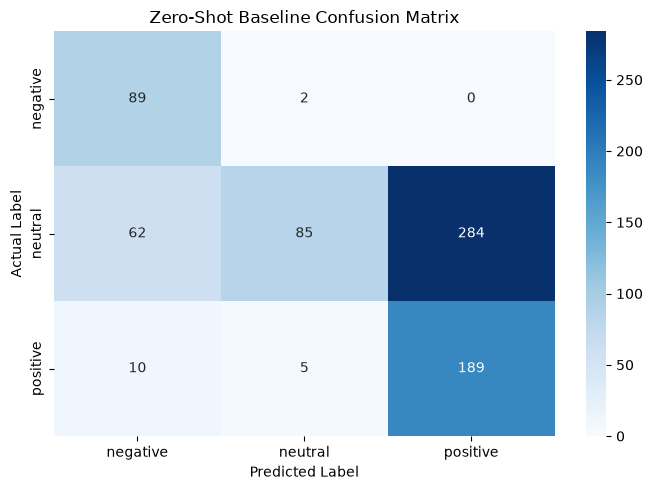

In [7]:
matrix = confusion_matrix(
    zero_shot_predictions["label"],
    zero_shot_predictions["predicted_label"],
    labels=LABELS
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.title("Zero-Shot Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    figures_dir / "zero_shot_confusion_matrix.png",
    dpi=200
)

plt.show()


In [8]:
metrics = {
    "model": MODEL_NAME,
    "evaluation_split": "held-out test set",
    "num_examples": int(len(zero_shot_predictions)),
    "accuracy": round(float(accuracy), 4),
    "macro_f1": round(float(macro_f1), 4),
    "per_class_f1": {
        label: round(float(report[label]["f1-score"]), 4)
        for label in LABELS
    }
}

with open(
    metrics_dir / "zero_shot_test_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metrics, file, indent=2)

zero_shot_predictions.to_csv(
    predictions_dir / "zero_shot_test_predictions.csv",
    index=False
)

print("\nSaved:")
print(metrics_dir / "zero_shot_test_metrics.json")
print(predictions_dir / "zero_shot_test_predictions.csv")
print(figures_dir / "zero_shot_confusion_matrix.png")


Saved:
c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\outputs\metrics\zero_shot_test_metrics.json
c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\outputs\predictions\zero_shot_test_predictions.csv
c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\outputs\figures\zero_shot_confusion_matrix.png
